# GSE111229: Mammary tumor fibroblast

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2020-05-02
> - Modified: 2026-01-10
---

> - Bartoschek, M., Oskolkov, N., Bocci, M. et al. Spatially and functionally distinct subclasses of breast cancer-associated fibroblasts revealed by single cell RNA sequencing. Nat Commun 9, 5150 (2018). https://doi.org/10.1038/s41467-018-07582-3
> - [GSE111229](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE111229)
> - Code availability: https://github.com/KPLab/SCS_CAF
> - Organism: Mus musculus
> - Tissue: Breast cancer-associated fibroblasts
> - Smart-seq2
> - 2018-12-04
---

# Experimental Design

> - Smart-Seq2 protocol
> - 92 spike-in
> - Illumina HiSeq 2000
> - STAR v2.3.0

| Sample | Strain | Tissue | Cell | Sorted | Gender | Age | Disease status |
| - | - | - | - | - | - | - | - |
| Donor | MMTV-PyMT mouse model | Mammary tumor fibroblast | Cancer-associated fibroblasts (CAFs) | EpCAM-, CD45-, CD31-, NG2- | - | 14 week | Breast tumors |

---

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(DESeq2))
suppressPackageStartupMessages(library(cowplot))

── Attaching core tidyverse packages ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.2
✔ purrr     1.2.1     
── Conflicts ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


# 1. Data Import

In [2]:
data_dir <- "~/data1/single_cell_dataset/TumorBiology/Mm_TumorFibroblast_SmartSeq2_GSE111229"

In [3]:
counts <- file.path(
    data_dir, "outs", "03_counts", "featureCounts.tsv") %>%
    read.table(header = TRUE, row.names = 1, sep = "\t") %>%
    rename_with(~ str_replace(
        .x, "^outs.02_star.(.*?).Aligned.out.bam$", "\\1"))

dim(counts)
counts[1:6, 5:14]

[1] 55335   775

,Length,gene_name,gene_type,SS2_15_0048_A1,SS2_15_0048_A10,SS2_15_0048_A11,SS2_15_0048_A12,SS2_15_0048_A13,SS2_15_0048_A14,SS2_15_0048_A15
,<int>,<chr>,<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
ENSMUSG00000102693.1,1070,4933401J01Rik,TEC,0,0,0,0,0,0,0
ENSMUSG00000064842.1,110,Gm26206,snRNA,0,0,0,0,0,0,0
ENSMUSG00000051951.5,6094,Xkr4,protein_coding,0,0,0,0,0,0,0
ENSMUSG00000102851.1,480,Gm18956,processed_pseudogene,0,0,0,0,0,0,0
ENSMUSG00000103377.1,2819,Gm37180,TEC,0,0,0,0,0,0,0
ENSMUSG00000104017.1,2233,Gm37363,TEC,0,0,0,0,0,0,0


In [4]:
counts.rna <- counts %>% 
    select(matches("^SS2")) %>%
    as.matrix()

dim(counts.rna)

[1] 55335   768

In [5]:
counts.ercc <- file.path(
    data_dir, "outs", "03_counts", "featureCounts_ERCC.tsv") %>%
    read.table(header = TRUE, row.names = 1, sep = "\t") %>%
    rename_with(~ str_replace(
        .x, "^outs.02_star.(.*?).Aligned.out.bam$", "\\1"))

anno.ercc <- counts.ercc %>% select(basepairs = Length)

counts.ercc <- counts.ercc %>% 
    select(matches("^SS2")) %>%
    as.matrix()

counts.ercc <- counts.ercc[rowMeans(counts.ercc) > 0, ]

anno.ercc <- anno.ercc[rownames(counts.ercc), , drop = FALSE]

dim(counts.ercc)

[1]  89 768

In [6]:
all(colnames(counts.rna) == colnames(counts.ercc))

[1] TRUE

In [7]:
star.summary <- file.path(
    data_dir, "outs", "02_star", "STAR_summary.tsv") %>%
    read.table(header = TRUE, sep = "\t") %>% 
    select(Sample, Uniquely_mapped_reads, Uniquely_mapped_pct)

In [8]:
counts.summary <- file.path(
    data_dir, "outs", "03_counts", "featureCounts.tsv.summary") %>%
    read.table(header = TRUE, row.names = 1, sep = "\t") %>%
    rename_with(~ str_replace(
        .x, "^outs.02_star.(.*?).Aligned.out.bam$", "\\1")) %>%
    t() %>% as.data.frame() %>%
    select(Assigned, Unassigned_NoFeatures, Unassigned_Ambiguity) %>%
    rownames_to_column("Sample") %>% 
    select(Sample, Assigned)

In [9]:
coldata <- colnames(counts.rna) %>%
    tibble(Sample = ., 
           nGene = colSums(counts.rna > 0),
           nCount = colSums(counts.rna), 
           nSpikein = colSums(counts.ercc)) %>%
    separate(col = Sample, into = c("SS2", "15", "Plate", "Index"), 
             sep = "_", fill = "right", extra = "drop", remove = FALSE) %>%
    left_join(star.summary, by = "Sample") %>%
    left_join(counts.summary, by = "Sample") %>%
    mutate(Pct_assigned = round(Assigned/Uniquely_mapped_reads *100, digits = 2),
           Pct_ercc = round(nSpikein/Uniquely_mapped_reads *100, digits = 2)) %>%
    column_to_rownames("Sample") %>%
    select(Plate, Index, nGene, nCount, nSpikein, Uniquely_mapped_pct, 
           Pct_assigned, Pct_ercc)

head(coldata)

,Plate,Index,nGene,nCount,nSpikein,Uniquely_mapped_pct,Pct_assigned,Pct_ercc
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
SS2_15_0048_A1,0048,A1,5574,307153,28021,98.46,77.47,7.07
SS2_15_0048_A10,0048,A10,4770,275388,38283,97.93,73.80,10.26
SS2_15_0048_A11,0048,A11,4698,227981,37925,99.16,66.91,11.13
SS2_15_0048_A12,0048,A12,5534,247081,22748,98.14,72.73,6.70
SS2_15_0048_A13,0048,A13,5288,266379,31740,98.10,74.97,8.93
SS2_15_0048_A14,0048,A14,4291,228132,44308,97.92,69.13,13.43


In [10]:
geneAnno <- counts %>% select(
    symbol = gene_name, type = gene_type, basepairs = Length) %>%
    rownames_to_column("gene_id")

head(geneAnno)

,gene_id,symbol,type,basepairs
,<chr>,<chr>,<chr>,<int>
1,ENSMUSG00000102693.1,4933401J01Rik,TEC,1070
2,ENSMUSG00000064842.1,Gm26206,snRNA,110
3,ENSMUSG00000051951.5,Xkr4,protein_coding,6094
4,ENSMUSG00000102851.1,Gm18956,processed_pseudogene,480
5,ENSMUSG00000103377.1,Gm37180,TEC,2819
6,ENSMUSG00000104017.1,Gm37363,TEC,2233


# 2. Quality Control

In [11]:
# # remove genes by only a few cells (lower than 2% of cells)
# counts.rna <- counts.rna[
#     rowSums(counts.rna > 0) > round(ncol(counts.rna) * 0.02), ]

# remove genes with fewer than one count on average over all cells
counts.rna <- counts.rna[rowMeans(counts.rna) >= 1, ]

dim(counts.rna)

[1] 11013   768

In [12]:
# Matrix sparsity
sparsity <- sum(counts.rna == 0) / (nrow(counts.rna) * ncol(counts.rna))
message(sprintf("Matrix sparsity: %.2f%%", sparsity * 100))

Matrix sparsity: 60.38%



In [13]:
geneAnno[match(rownames(counts.rna), geneAnno$gene_id), ] %>% 
    dplyr::count(symbol) %>%
    filter(n > 1) %>%
    pull(symbol)

character(0)

In [14]:
geneAnno <- geneAnno %>%
    filter(gene_id %in% rownames(counts.rna)) %>%
    column_to_rownames("symbol")

In [15]:
counts.rna <- counts.rna %>% as.data.frame() %>%
    rownames_to_column("gene_id") %>%
    left_join(
        geneAnno %>% rownames_to_column("symbol") %>% 
            select(gene_id, symbol), by = "gene_id") %>%
    select(-gene_id) %>%
    column_to_rownames("symbol") %>%
    as.matrix()

In [16]:
eSet <- SummarizedExperiment(
    assays = list(counts = counts.rna), 
    rowData = geneAnno,
    colData = coldata)
eSet

class: SummarizedExperiment 
dim: 11013 768 
metadata(0):
assays(1): counts
rownames(11013): Mrpl15 Lypla1 ... mt-Cytb mt-Tp
rowData names(3): gene_id type basepairs
colnames(768): SS2_15_0048_A1 SS2_15_0048_A10 ... SS2_15_0049_P8
  SS2_15_0049_P9
colData names(8): Plate Index ... Pct_assigned Pct_ercc

In [17]:
cols <-  c("nGene", "nCount", "nSpikein", "Uniquely_mapped_pct", "Pct_assigned", "Pct_ercc")

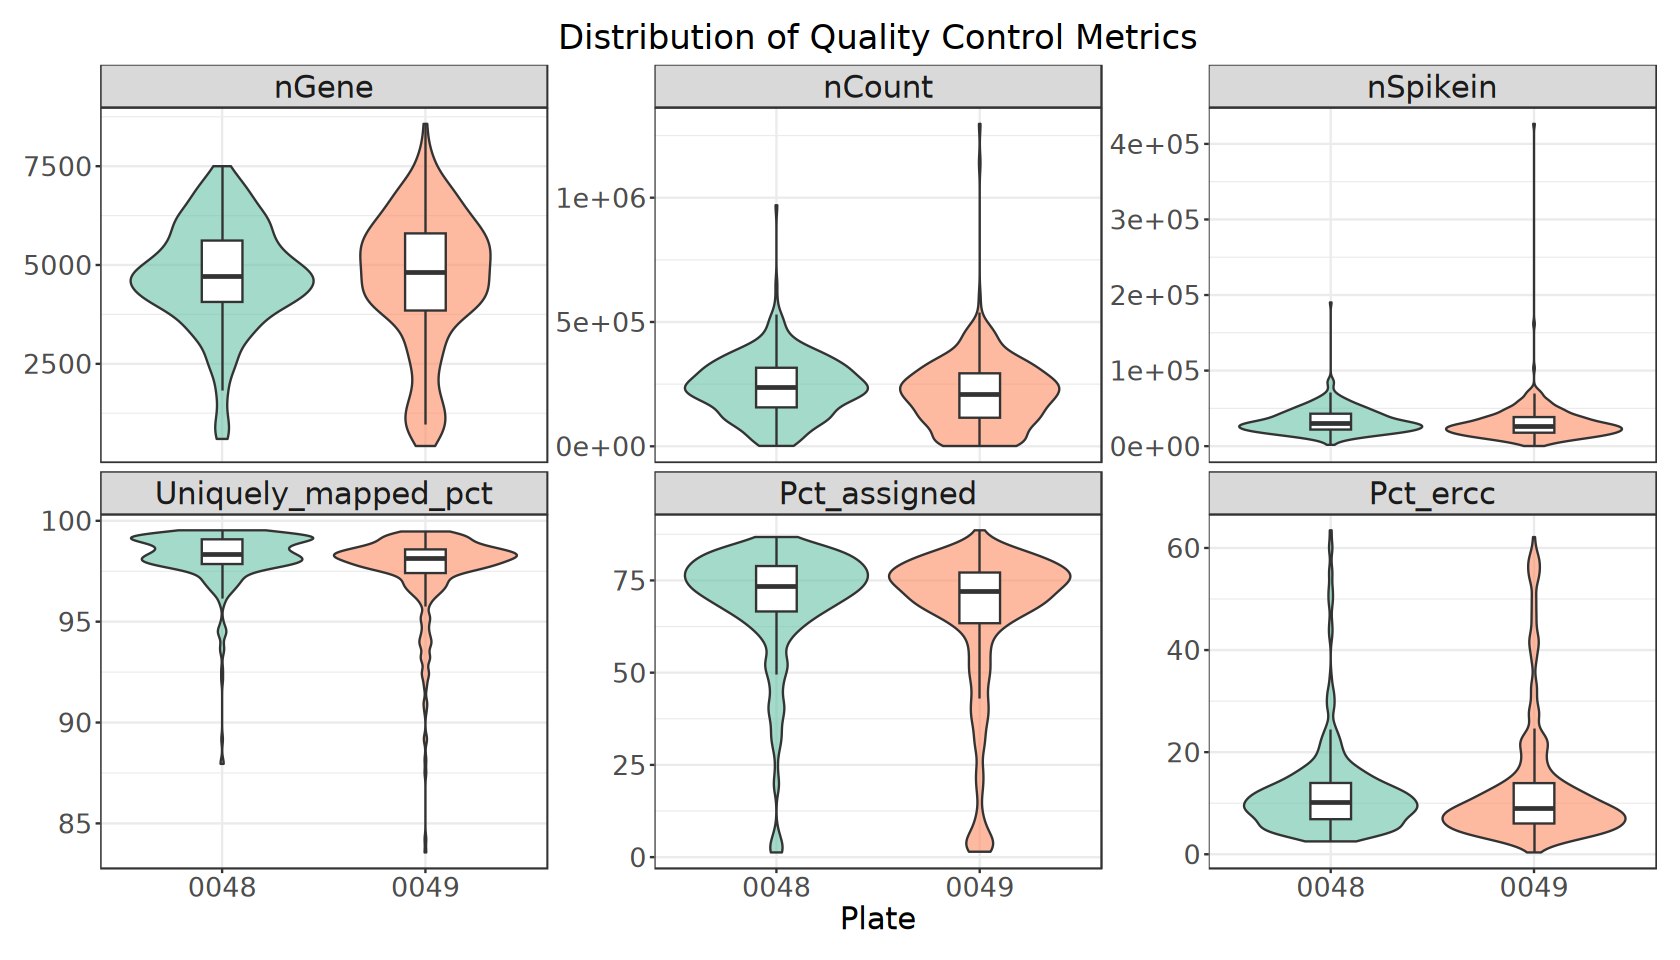

In [18]:
options(repr.plot.width = 14, repr.plot.height = 8)

colData(eSet) %>% as.data.frame() %>%
    select(all_of(c("Plate", cols))) %>%
    pivot_longer(
        cols = all_of(cols), names_to = "Metric", values_to = "Value") %>%
    mutate(Metric = factor(Metric, levels = cols)) %>%
    ggplot(aes(x = Plate, y = Value)) +
        geom_violin(aes(fill = Plate), width = 0.9, alpha = 0.6,
                    trim = TRUE, show.legend = FALSE) +
        geom_boxplot(width = 0.2, outlier.shape = NA, fill = "white") +
        scale_fill_brewer(palette = "Set2") +
        facet_wrap(~ Metric, scales = "free_y") + 
        labs(title = "Distribution of Quality Control Metrics", 
             x = "Plate", y = NULL) +
        theme_bw() +
        theme(plot.title = element_text(size = 20, hjust = 0.5),
              strip.text = element_text(size = 18), 
              axis.title = element_text(size = 18), 
              axis.text = element_text(size = 16), 
              plot.margin = unit(c(1, 1, 1, 1), "line"))

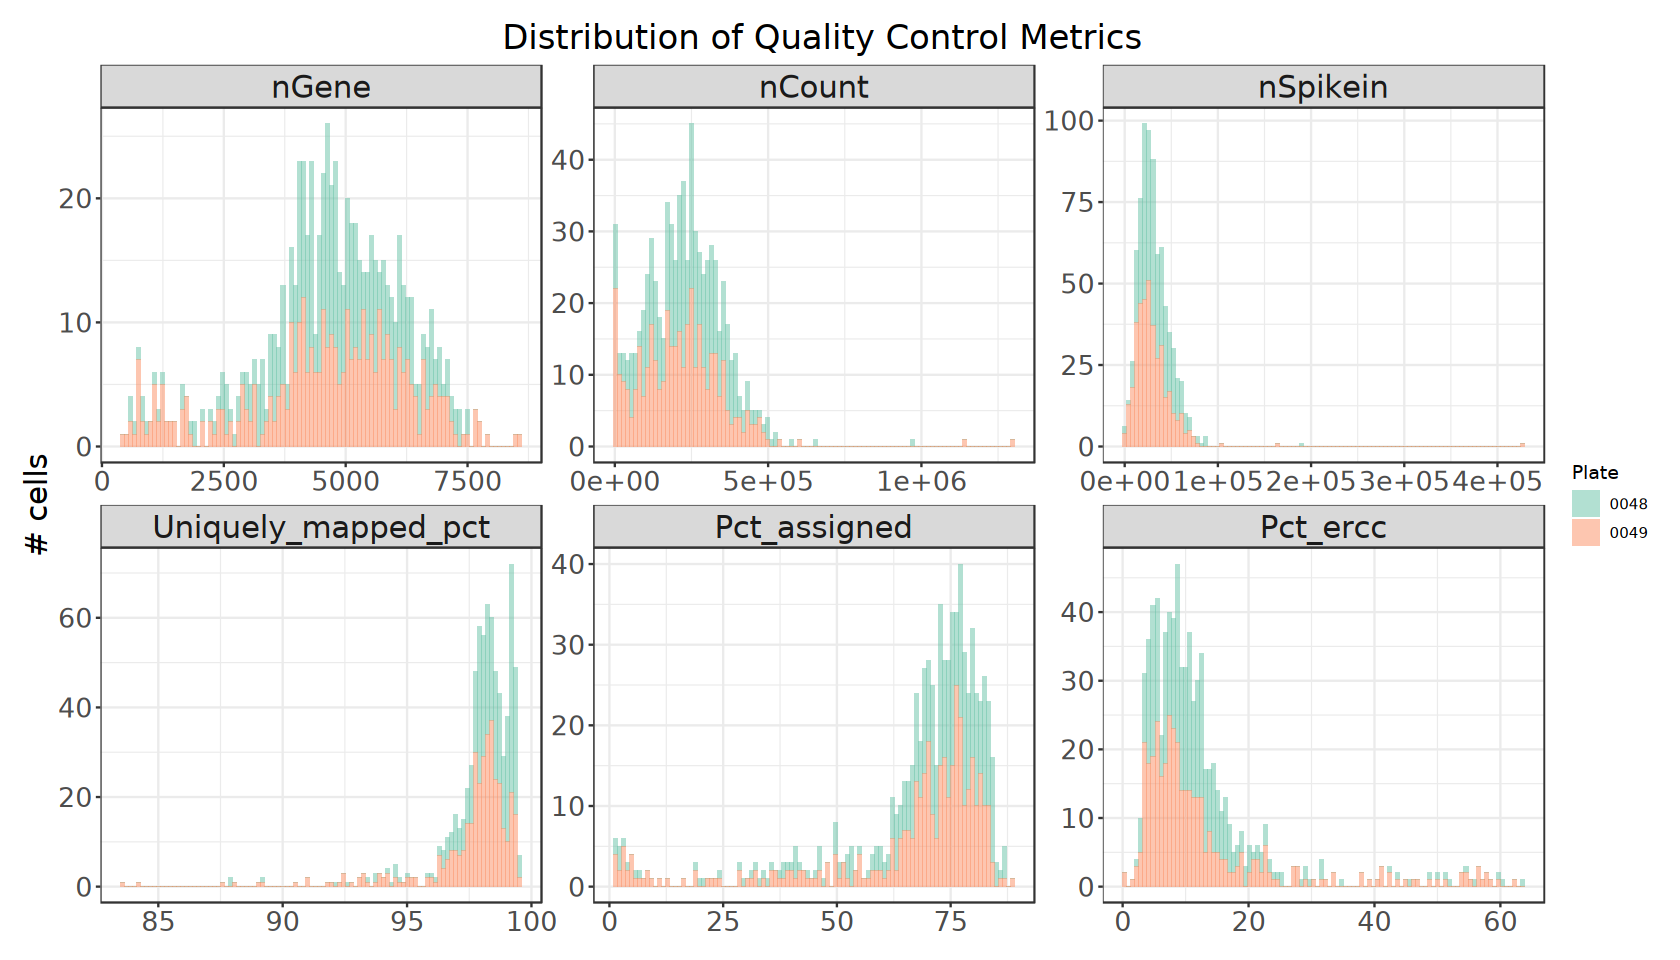

In [19]:
options(repr.plot.width = 14, repr.plot.height = 8)
colData(eSet) %>% as.data.frame() %>%
    select(all_of(c("Plate", cols))) %>%
    pivot_longer(
        cols = all_of(cols), names_to = "Metric", values_to = "Value") %>%
    mutate(Metric = factor(Metric, levels = cols)) %>%
    ggplot(aes(y = Value, fill = Plate)) +
        geom_histogram(bins = 100, alpha = 0.5) +
        scale_fill_brewer(palette = "Set2") +
        facet_wrap(~ Metric, scales = "free") + 
        coord_flip() + 
        labs(title = "Distribution of Quality Control Metrics", 
             x = "# cells", y = NULL) +
        theme_bw() +
        theme(plot.title = element_text(size = 20, hjust = 0.5),
              strip.text = element_text(size = 18), 
              axis.title = element_text(size = 18), 
              axis.text = element_text(size = 16), 
              plot.margin = unit(c(1, 1, 1, 1), "line"))

In [20]:
colData(eSet)[, cols] %>% as.data.frame() %>% summary()

     nGene          nCount           nSpikein      Uniquely_mapped_pct
 Min.   : 421   Min.   :   1225   Min.   :   226   Min.   :83.56      
 1st Qu.:3954   1st Qu.: 129378   1st Qu.: 19961   1st Qu.:97.65      
 Median :4765   Median : 225978   Median : 28370   Median :98.21      
 Mean   :4664   Mean   : 225404   Mean   : 32104   Mean   :97.84      
 3rd Qu.:5699   3rd Qu.: 306931   3rd Qu.: 40491   3rd Qu.:98.83      
 Max.   :8571   Max.   :1297007   Max.   :426516   Max.   :99.53      
  Pct_assigned      Pct_ercc     
 Min.   : 1.27   Min.   : 0.360  
 1st Qu.:64.96   1st Qu.: 6.500  
 Median :72.98   Median : 9.585  
 Mean   :66.92   Mean   :12.647  
 3rd Qu.:77.97   3rd Qu.:13.940  
 Max.   :88.59   Max.   :63.460  

In [21]:
eSet <- subset(
    eSet, 
    select = nCount > 10000 & Pct_assigned > 30 & Pct_ercc > 1)
eSet

counts.ercc <- counts.ercc[, colnames(eSet)]
dim(counts.ercc)

class: SummarizedExperiment 
dim: 11013 717 
metadata(0):
assays(1): counts
rownames(11013): Mrpl15 Lypla1 ... mt-Cytb mt-Tp
rowData names(3): gene_id type basepairs
colnames(717): SS2_15_0048_A1 SS2_15_0048_A10 ... SS2_15_0049_P8
  SS2_15_0049_P9
colData names(8): Plate Index ... Pct_assigned Pct_ercc

[1]  89 717

# 3. Normalization

In [22]:
# Calculate spike-in-based size factor
sf_spike <- eSet$nSpikein / median(eSet$nSpikein, na.rm = TRUE)

assay(eSet, "spikein") <- sweep(assay(eSet), 2, sf_spike, FUN = "/")

In [23]:
# FPKM
assay(eSet, "fpkm") <- assay(eSet, "counts") %>% 
    sweep(1, rowData(eSet)$basepairs / 1e3, FUN = "/") %>%
    sweep(2, colSums(assay(eSet, "counts")) / 1e6, FUN = "/")

In [24]:
# TPM
assay(eSet, "tpm") <- assay(eSet, "counts") %>% 
    sweep(1, rowData(eSet)$basepairs, FUN = "/") %>% 
    (\(rpk) sweep(rpk, 2, colSums(rpk), FUN = "/") * 1e6)()

In [25]:
eSet

class: SummarizedExperiment 
dim: 11013 717 
metadata(0):
assays(4): counts spikein fpkm tpm
rownames(11013): Mrpl15 Lypla1 ... mt-Cytb mt-Tp
rowData names(3): gene_id type basepairs
colnames(717): SS2_15_0048_A1 SS2_15_0048_A10 ... SS2_15_0049_P8
  SS2_15_0049_P9
colData names(8): Plate Index ... Pct_assigned Pct_ercc

# 4. Filter Variable Genes

## a). SD

In [26]:
top_sd_idx <- log2(assay(eSet, "fpkm") + 1) %>% 
    rowSds() %>% 
    tibble::enframe(name = "row", value = "sd") %>% 
    slice_max(order_by = sd, n = 1000) %>% 
    pull(row)

## b). CV^2

In [27]:
library_size <- eSet$nCount + eSet$nSpikein

In [28]:
counts.rna.fpkm <- assay(eSet, "counts") %>% 
    sweep(1, rowData(eSet)$basepairs / 1e3, FUN = "/") %>%
    sweep(2, library_size / 1e6, FUN = "/")

counts.rna.fpkm <- counts.rna.fpkm[rowMeans(counts.rna.fpkm) >= 1, ]

gene_stats <- counts.rna.fpkm %>% {
    tibble(gene = rownames(.), mean = rowMeans(.),
           sd = rowSds(.), cv2 = (sd / mean)^2)
}

In [29]:
counts.ercc.fpkm <- counts.ercc %>%
    sweep(1, anno.ercc$basepairs / 1e3, FUN = "/") %>%
    sweep(2, library_size / 1e6, FUN = "/")

counts.ercc.fpkm <- counts.ercc.fpkm[rowMeans(counts.ercc.fpkm) >= 1, ]

ercc_stats <- counts.ercc.fpkm %>% {
    tibble(gene = rownames(.), mean = rowMeans(.),
           sd = rowSds(.), cv2 = (sd / mean)^2)
} %>% filter(is.finite(log10(mean)))

In [30]:
ercc_fit <- loess(
    log10(cv2) ~ log10(mean), data = ercc_stats, span = 1)
ercc_fit

Call:
loess(formula = log10(cv2) ~ log10(mean), data = ercc_stats, 
    span = 1)

Number of Observations: 64 
Equivalent Number of Parameters: 3.44 
Residual Standard Error: 0.164 

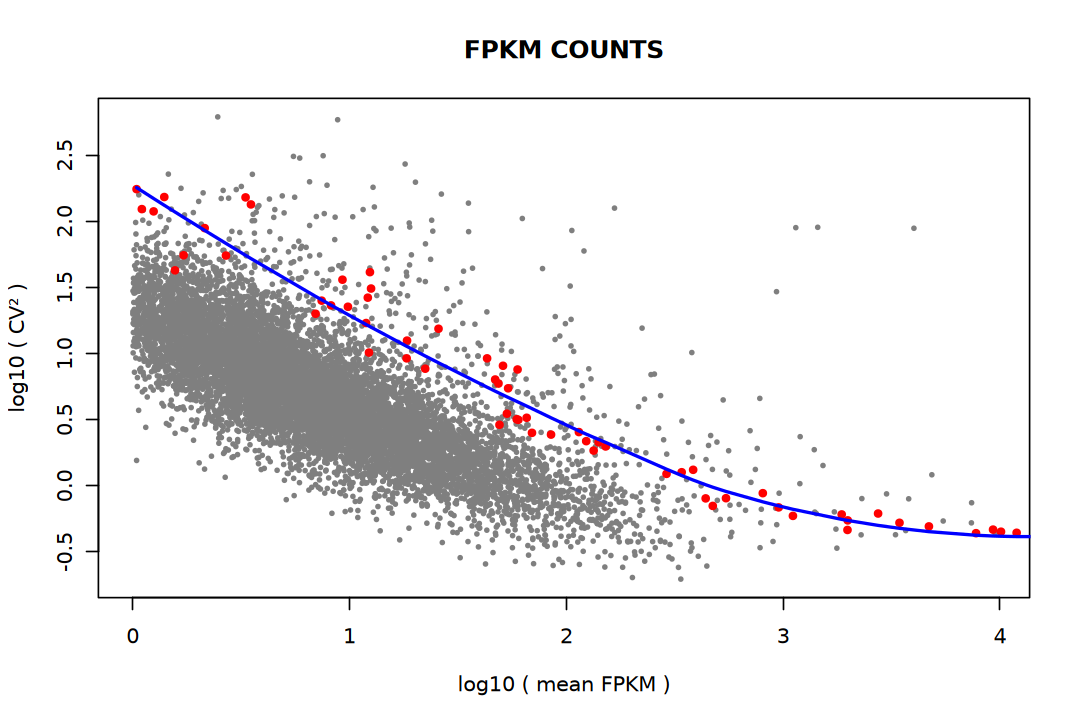

In [31]:
options(repr.plot.width = 9, repr.plot.height = 6)

plot(log10(gene_stats$cv2) ~ log10(gene_stats$mean),
     pch = 20, cex = 0.5, col = "grey50",
     main = "FPKM COUNTS",
     xlab = "log10 ( mean FPKM )",
     ylab = "log10 ( CV² )")

points(log10(ercc_stats$cv2) ~ log10(ercc_stats$mean),
       col = "red", pch = 20, cex = 1)

ercc_stats %>% arrange(mean) %>% {
    lines(predict(ercc_fit, log10(.$mean)) ~ log10(.$mean), 
          col = "blue", lwd = 2)
}

In [32]:
top_cv2_idx <- gene_stats %>%
    mutate(pred_cv2 = predict(ercc_fit, log10(mean)),
           variable = log10(cv2) >= pred_cv2 - 0.2) %>%
    filter(variable) %>%
    pull(gene)

In [33]:
length(top_cv2_idx)

[1] 548

In [ ]:
library(ggpubr)
ggscatter(cv_per_gene[-grep("ERCC",rownames(cv_per_gene)),],
          x = 'log10mean', y = 'log10cv2',
          color = "black", shape = 16, size = 1,
          xlab = 'log10(mean)', ylab = "log10(CV^2)",
          mean.point = T,
          cor.coeff.args = list(method = "spearman"), 
          label.x = 3,label.sep = "\n",
          dot.size = 2,
          ylim=c(-0.5, 2.5),
          xlim=c(0,4),
          ggp = ggscatter(cv_per_gene[grep("ERCC",rownames(cv_per_gene)),], 
                          x = 'log10mean', y = 'log10cv2',
                          color = "red", shape = 16, size = 1, 
                          xlab = 'log10(mean RPKM)', ylab = "log10(CV^2)",
                          add = "loess",
                          mean.point=T,
                          add.params = list(color = "red",fill = "lightgray"),
                          cor.coeff.args = list(method = "pearson"), 
                          label.x = 3,label.sep = "\n",
                          dot.size = 2,
          )
)


In [34]:
suppressPackageStartupMessages(library(ggVennDiagram))

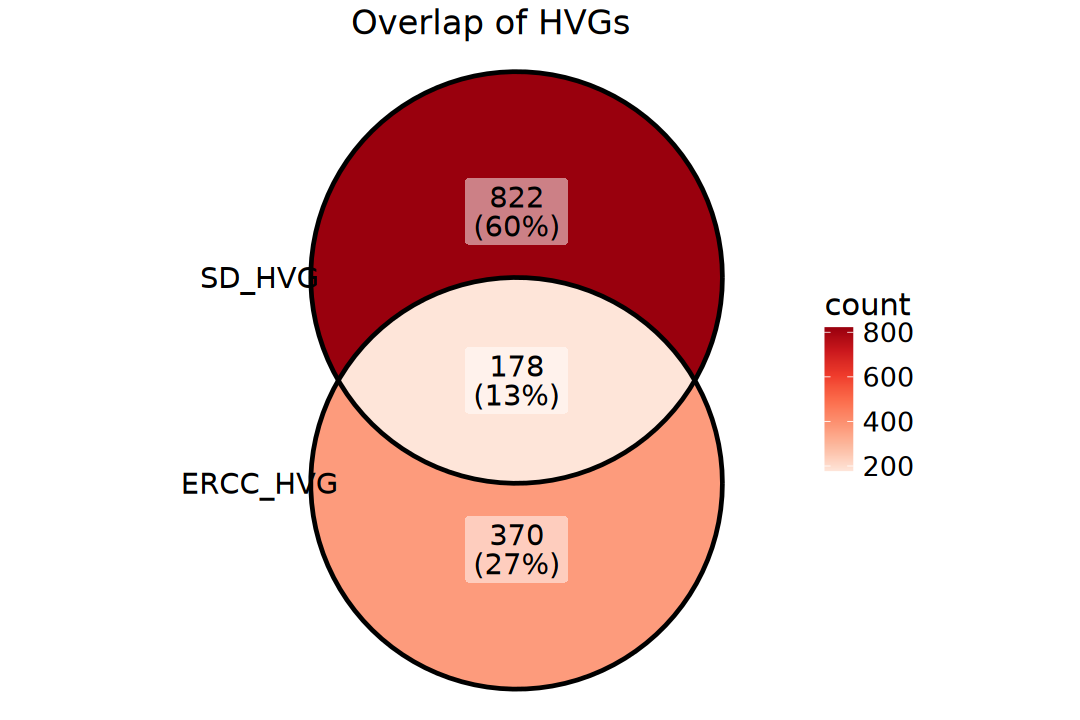

In [35]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggVennDiagram(
    list(ERCC_HVG = top_cv2_idx, SD_HVG = top_sd_idx), 
    set_size = 6, label_alpha = 0.5, label_size = 6) +
    scale_fill_distiller(palette = "Reds", direction = 1) + 
    scale_x_continuous(expand = expansion(mult = .2)) + 
    ggtitle("Overlap of HVGs") + 
    theme(plot.title = element_text(size = 20, hjust = 0.5), 
          legend.title = element_text(size = 18),
          legend.text = element_text(size = 16))

# 5. PCA

In [36]:
normExpr <- log2(assay(eSet, "tpm") + 1)

In [37]:
pca_res <- normExpr[top_cv2_idx, ] %>% t() %>% 
    prcomp(center = TRUE, scale. = FALSE)

per_var <- round(100 * pca_res$sdev^2 / sum(pca_res$sdev^2), 2)

pca_df <- merge(pca_res$x[, 1:3], colData(eSet), by = "row.names")

In [38]:
head(pca_df)

,Row.names,PC1,PC2,PC3,Plate,Index,nGene,nCount,nSpikein,Uniquely_mapped_pct,Pct_assigned,Pct_ercc
,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,SS2_15_0048_A1,-15.31282,-20.7618733,-26.321656,0048,A1,5574,307153,28021,98.46,77.47,7.07
2,SS2_15_0048_A10,-24.92241,-13.6949563,-12.808369,0048,A10,4770,275388,38283,97.93,73.80,10.26
3,SS2_15_0048_A11,38.82284,-0.3895977,12.780529,0048,A11,4698,227981,37925,99.16,66.91,11.13
4,SS2_15_0048_A12,51.62484,-8.1303950,3.383789,0048,A12,5534,247081,22748,98.14,72.73,6.70
5,SS2_15_0048_A13,-16.12943,-6.8481820,-6.304962,0048,A13,5288,266379,31740,98.10,74.97,8.93
6,SS2_15_0048_A14,-14.27538,-10.3767923,-6.869942,0048,A14,4291,228132,44308,97.92,69.13,13.43


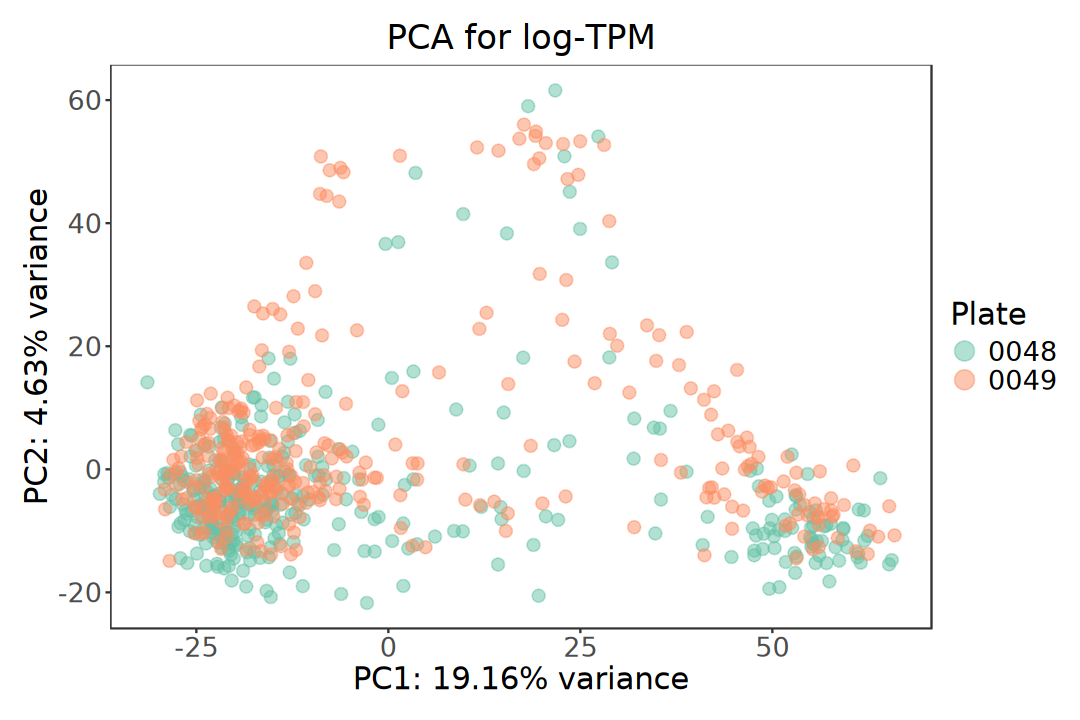

In [39]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(pca_df, aes(PC1, PC2)) +
    geom_point(aes(color = Plate), size = 3, alpha = 0.5) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "PCA for log-TPM", 
         x = paste0("PC1: ", per_var[1], "% variance"),
         y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(color = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(plot.title = element_text(size = 20, hjust = 0.5), 
          legend.title = element_text(size = 18), 
          legend.text = element_text(size = 16),
          axis.title = element_text(size = 18), 
          axis.text = element_text(size = 16), 
          plot.margin = unit(c(1, 1, 1, 1), "line"))

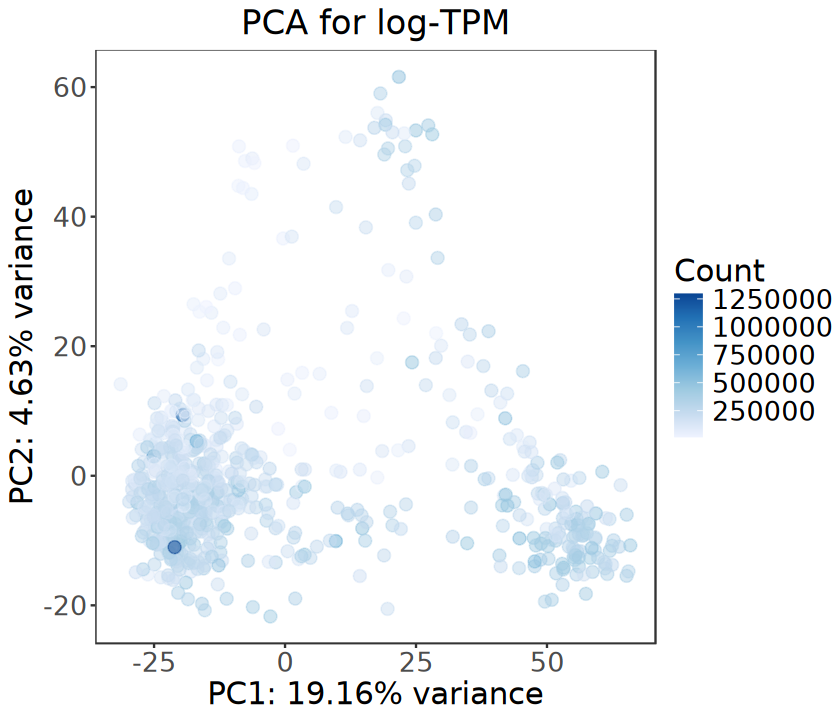

In [90]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(pca_df, aes(PC1, PC2)) +
    geom_point(aes(color = nCount), size = 3, alpha = 0.5) +
    scale_color_distiller(palette = "Blues", direction = 1) + 
    # scale_color_gradient(low = "grey", high = "blue") +
    labs(title = "PCA for log-TPM", 
         x = paste0("PC1: ", per_var[1], "% variance"),
         y = paste0("PC2: ", per_var[2], "% variance"),
         color = "Count") +
    theme_test() +
    theme(plot.title = element_text(size = 20, hjust = 0.5), 
          legend.title = element_text(size = 18), 
          legend.text = element_text(size = 16),
          axis.title = element_text(size = 18), 
          axis.text = element_text(size = 16))

# 6. t-SNE

In [41]:
suppressPackageStartupMessages(library(Rtsne))

In [42]:
# t-SNE
set.seed(123)
tsne <- normExpr[top_cv2_idx, ] %>% t() %>%
    Rtsne(pca = TRUE, initial_dims = 30, perplexity = 27, theta = 0.5, 
          max_iter = 5000, check_duplicates = FALSE, verbose = FALSE)

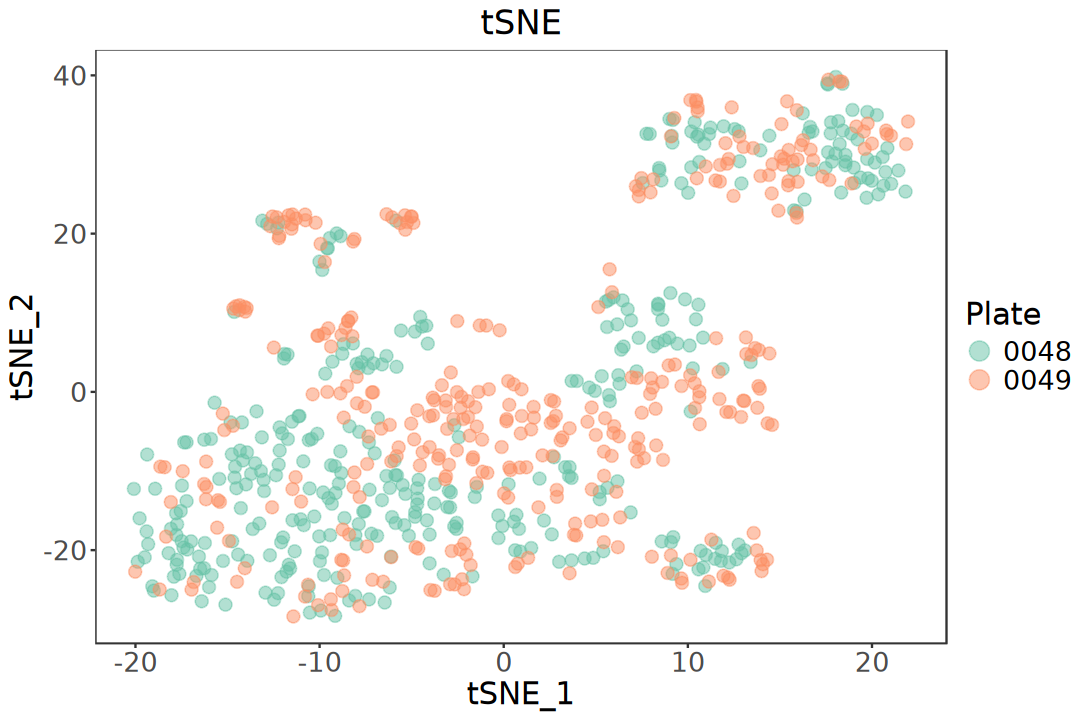

In [43]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(tsne$Y %>% as.data.frame(), aes(V1, V2)) +
    geom_point(aes(color = eSet$Plate), size = 3, alpha = 0.5) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "tSNE", x = "tSNE_1", y = "tSNE_2") +
    guides(color = guide_legend(
        title = "Plate", override.aes = list(size = 5))) +
    theme_test() +
    theme(plot.title = element_text(size = 20, hjust = 0.5), 
          legend.title = element_text(size = 18), 
          legend.text = element_text(size = 16),
          axis.title = element_text(size = 18), 
          axis.text = element_text(size = 16))

# 7. Clustering

## a). hclust

In [109]:
# clust
hc <- normExpr[top_cv2_idx, ] %>% t() %>% dist() %>% hclust()

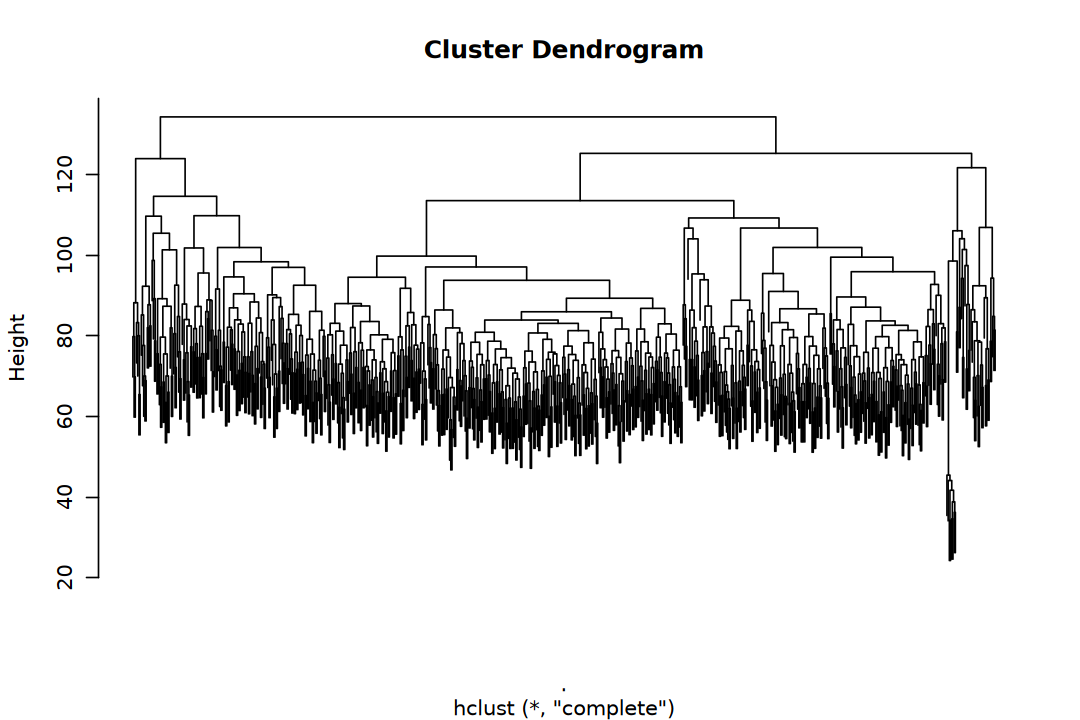

In [110]:
options(repr.plot.width = 9, repr.plot.height = 6)
plot(hc, labels = FALSE)

In [115]:
eSet$cluster_hclust <- cutree(hc, 4) %>% factor()

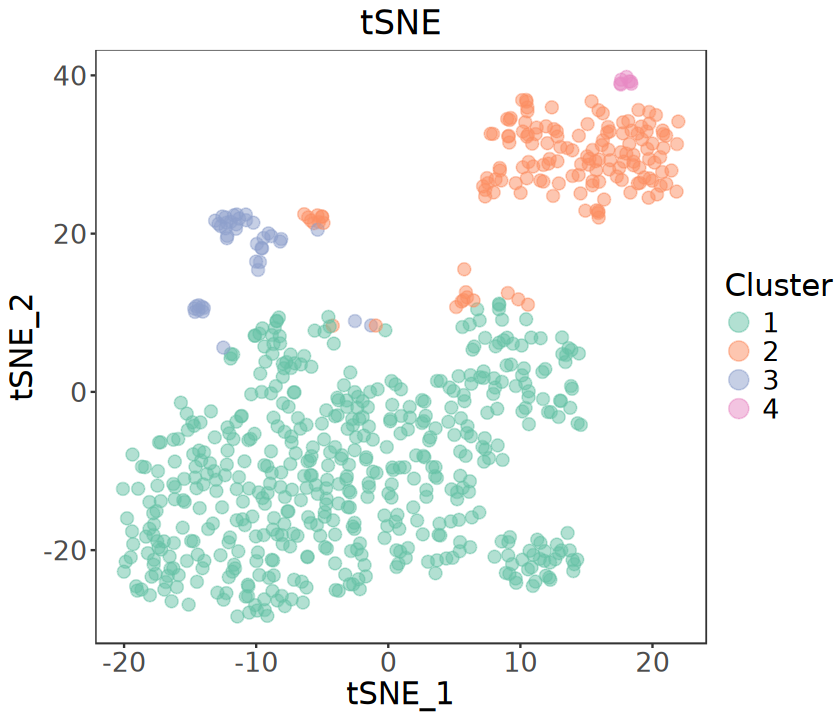

In [116]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(tsne$Y %>% as.data.frame(), aes(V1, V2)) +
    geom_point(aes(color = eSet$cluster_hclust), 
               size = 3, alpha = 0.5) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "tSNE", x = "tSNE_1", y = "tSNE_2") +
    guides(color = guide_legend(
        title = "Cluster", override.aes = list(size = 5))) +
    theme_test() +
    theme(plot.title = element_text(size = 20, hjust = 0.5), 
          legend.title = element_text(size = 18), 
          legend.text = element_text(size = 16),
          axis.title = element_text(size = 18), 
          axis.text = element_text(size = 16))

## 2). [DBSCAN](https://github.com/mhahsler/dbscan)

Density-Based Spatial Clustering of Applications with Noise (DBSCAN) and Related Algorithms

In [117]:
suppressPackageStartupMessages(library(dbscan))

In [118]:
cluster_group <- dbscan(tsne$Y, eps = 3.1, minPts = 5)

In [119]:
eSet$cluster_dbscan <- factor(cluster_group$cluster)

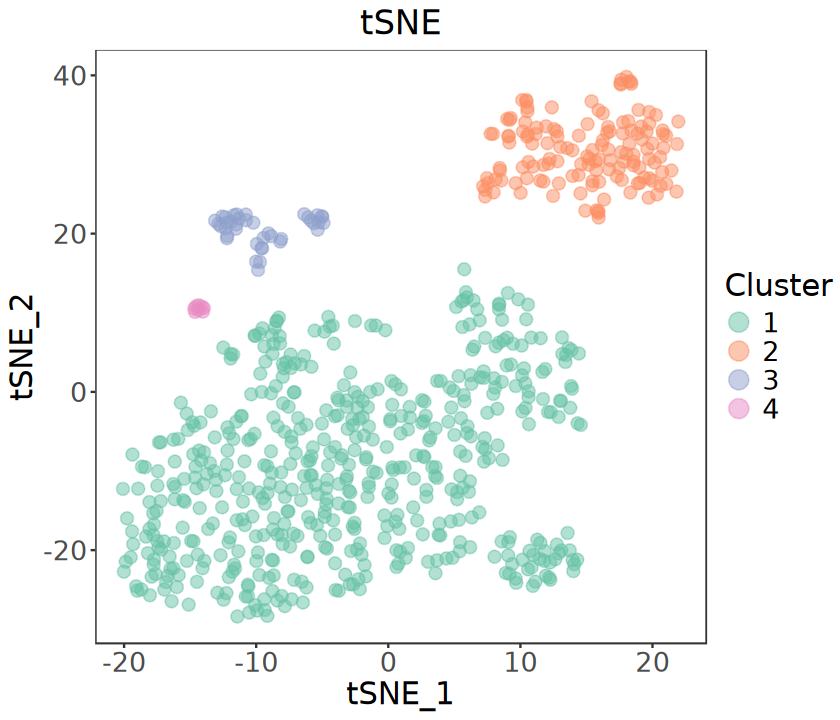

In [120]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(tsne$Y %>% as.data.frame(), aes(V1, V2)) +
    geom_point(aes(color = eSet$cluster_dbscan), 
               size = 3, alpha = 0.5) +
    scale_color_brewer(palette = "Set2") +
    labs(title = "tSNE", x = "tSNE_1", y = "tSNE_2") +
    guides(color = guide_legend(
        title = "Cluster", override.aes = list(size = 5))) +
    theme_test() +
    theme(plot.title = element_text(size = 20, hjust = 0.5), 
          legend.title = element_text(size = 18), 
          legend.text = element_text(size = 16),
          axis.title = element_text(size = 18), 
          axis.text = element_text(size = 16))

## K means

In [ ]:
library(cluster)
set.seed(1234)
fit.km <- kmeans(df, 3, nstart=25)

In [ ]:
## step 9: Result visualization and Interpreting class
# * test 2.  method 1: K means clustering
fit.km$size
fit.km$centers
aggregate(testData[-1], by=list(cluster=fit.km$cluster), mean)

ct.km <- table(testData$Type, fit.km$cluster)
library(flexclust)
randIndex(ct.km)


## Other

In [ ]:
## step 6: Determines the number of classes
# method 1
wssplot <- function(data, nc=15, seed=1234){
  wss <- (nrow(data)-1)*sum(apply(data,2,var))
  for (i in 2:nc){
    set.seed(seed)
    wss[i] <- sum(kmeans(data, centers=i)$withinss)}
  plot(1:nc, wss, type="b", xlab="Number of Clusters",
       ylab="Within groups sum of squares")}
wssplot(rpkmNormalized1)

In [ ]:
# method 2
library(NbClust)
set.seed(1234)
devAskNewPage(ask=TRUE)
nc <- NbClust(rpkmNormalized1, min.nc=2, max.nc=15, method="kmeans")
table(nc$Best.n[1,])
barplot(table(nc$Best.n[1,]),
        xlab="Number of Clusters", ylab="Number of Criteria",
        main="Number of Clusters Chosen by 26 Criteria")


In [ ]:
# * test 3.  method 2: PAM clustering
set.seed(1234)
fit.pam <- pam(testData[-1], k=3, stand=TRUE)

# * test 3.  method 2: PAM clustering
fit.pam$medoids
clusplot(fit.pam, main="Bivariate Cluster Plot")

ct.pam <- table(testData$Type, fit.pam$clustering)
randIndex(ct.pam)

# 8. Cell Annotation

In [102]:
dotplot <- function(dat, df, features) {
    ggplot(df$Y %>% as.data.frame(), aes(V1, V2)) +
        geom_point(aes(color = dat[features, ]), 
                   size = 3, alpha = 0.5) +
        scale_color_distiller(palette = "YlOrRd", direction = 1) + 
        labs(title = features, x = "tSNE_1", y = "tSNE_2", 
             color = "log2 (TPM)") +
        theme_test() +
        theme(plot.title = element_text(size = 20, hjust = 0.5), 
              legend.title = element_text(size = 18), 
              legend.text = element_text(size = 16),
              axis.title = element_text(size = 18), 
              axis.text = element_text(size = 16))
}

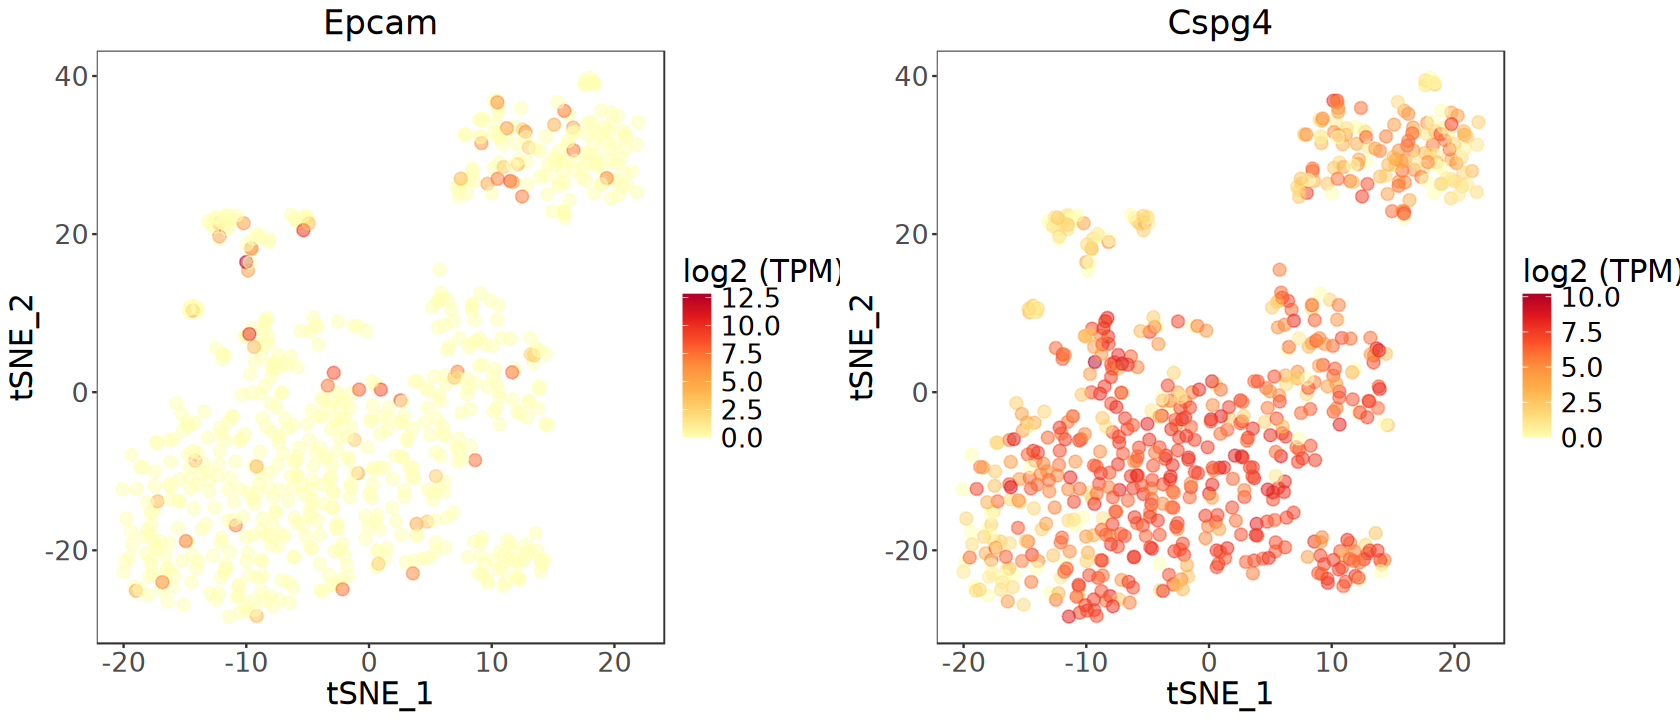

In [103]:
options(repr.plot.width = 14, repr.plot.height = 6)

plot_list <- lapply(
    c("Epcam", "Cspg4"), dotplot, dat = normExpr, df = tsne)

plot_grid(plotlist = plot_list, ncol = 2)

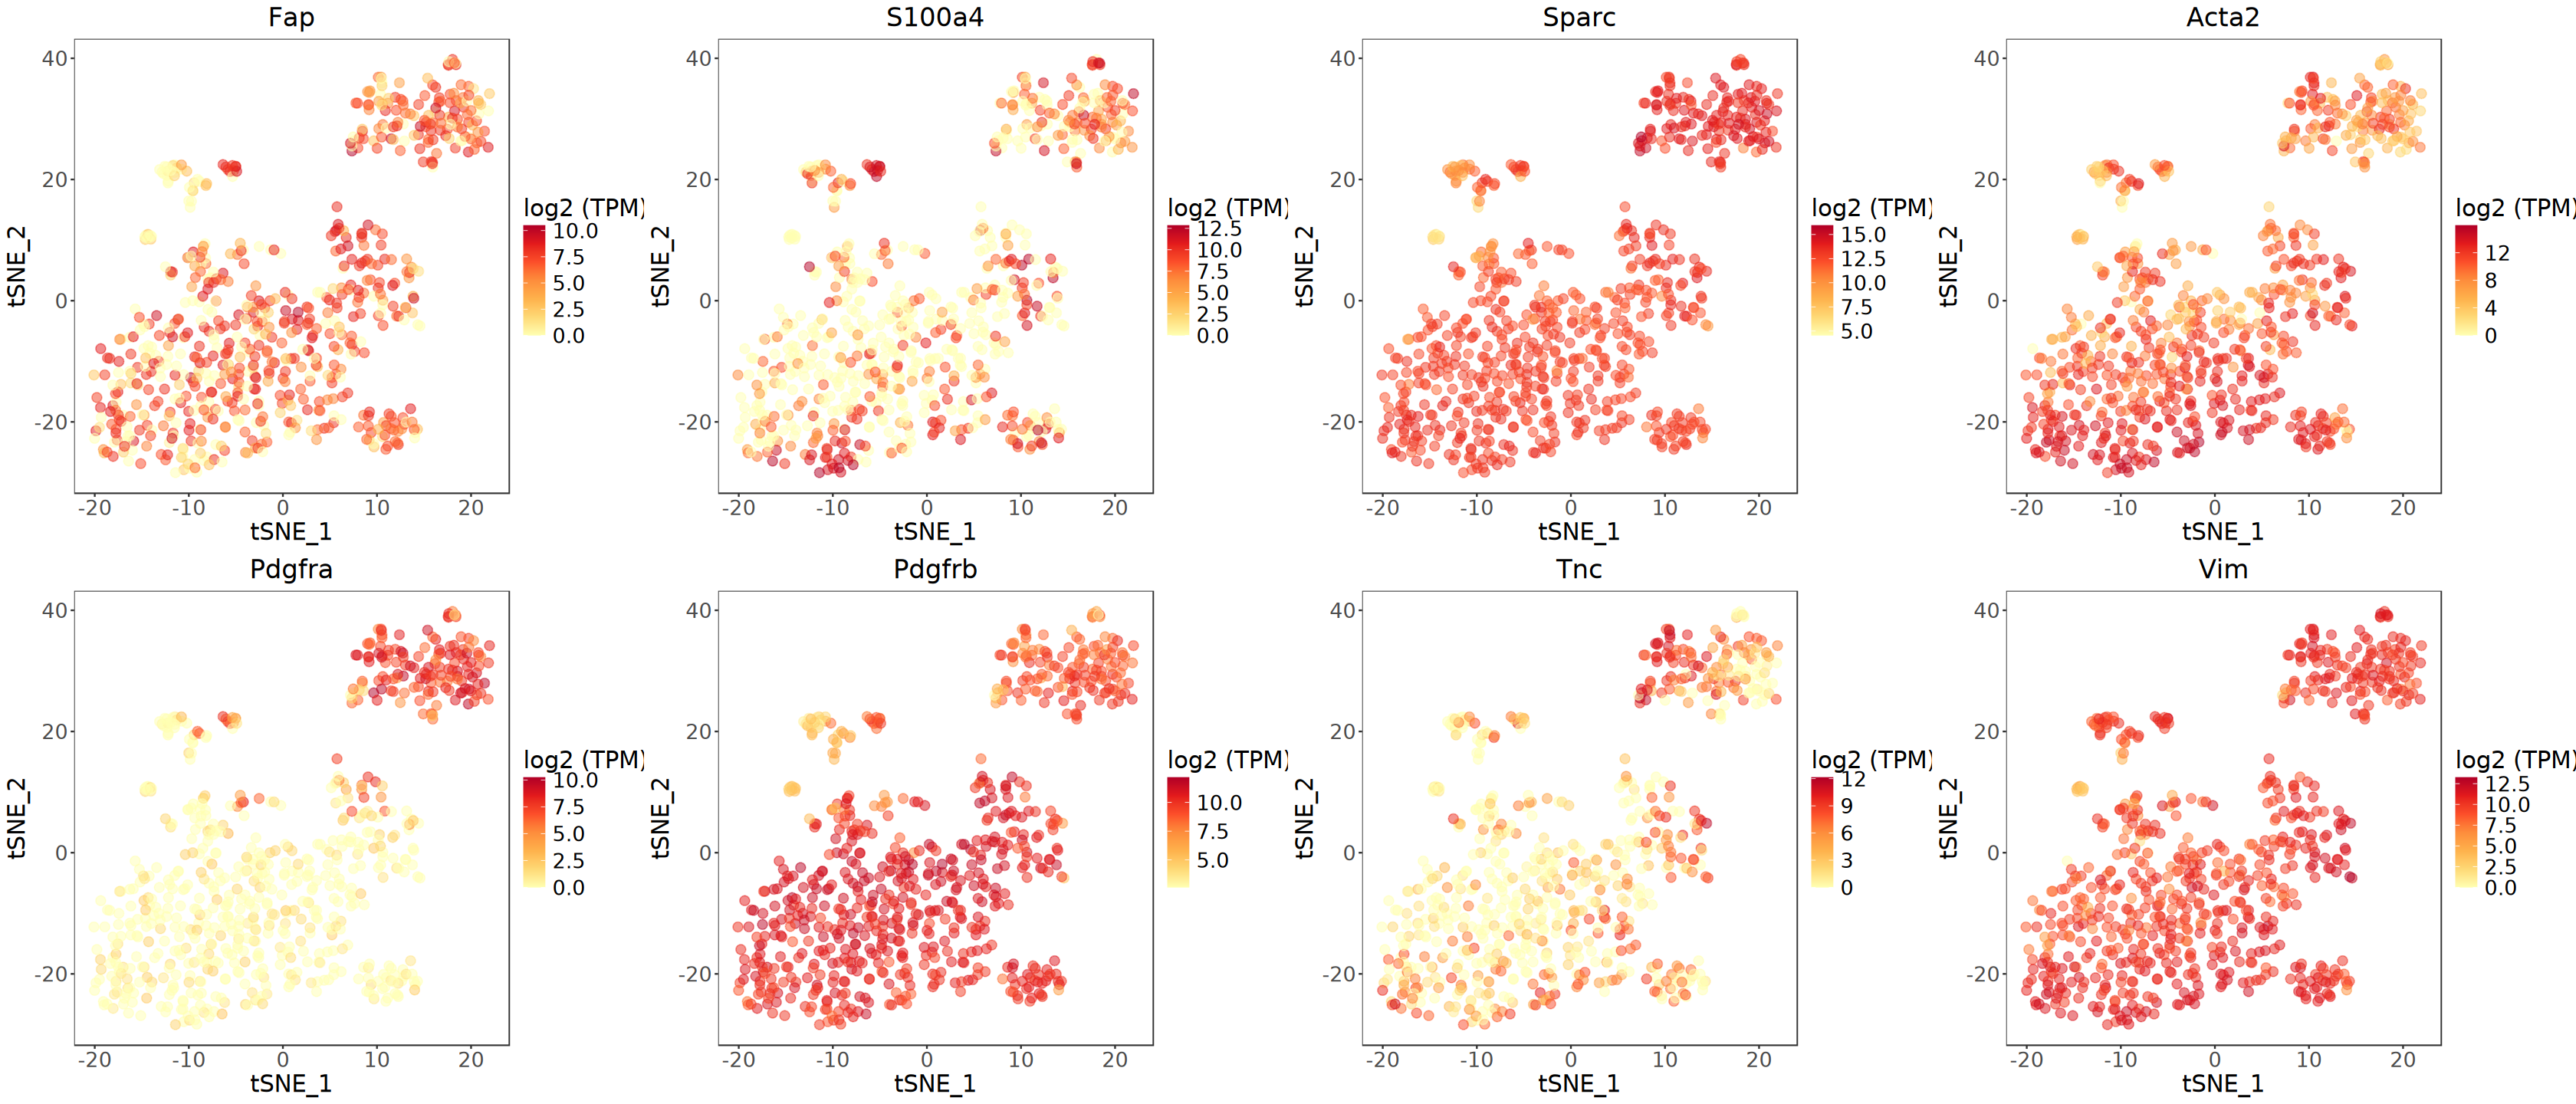

In [104]:
options(repr.plot.width = 28, repr.plot.height = 12)

plot_list <- lapply(
    c("Fap", "S100a4", "Sparc", "Acta2", "Pdgfra", "Pdgfrb", "Tnc", "Vim"), 
    dotplot, dat = normExpr, df = tsne)

plot_grid(plotlist = plot_list, ncol = 4)

# 9. Vis

In [107]:
suppressPackageStartupMessages(library(pheatmap))

In [121]:
ac <- colData(eSet) %>% as.data.frame() %>%
    dplyr::select(Plate, cluster = cluster_dbscan)

group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(2),
    unique(eSet$Plate))
cluster_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(4),
    unique(eSet$cluster))

anno_colors <- list(Plate = group_colors, cluster = cluster_colors)

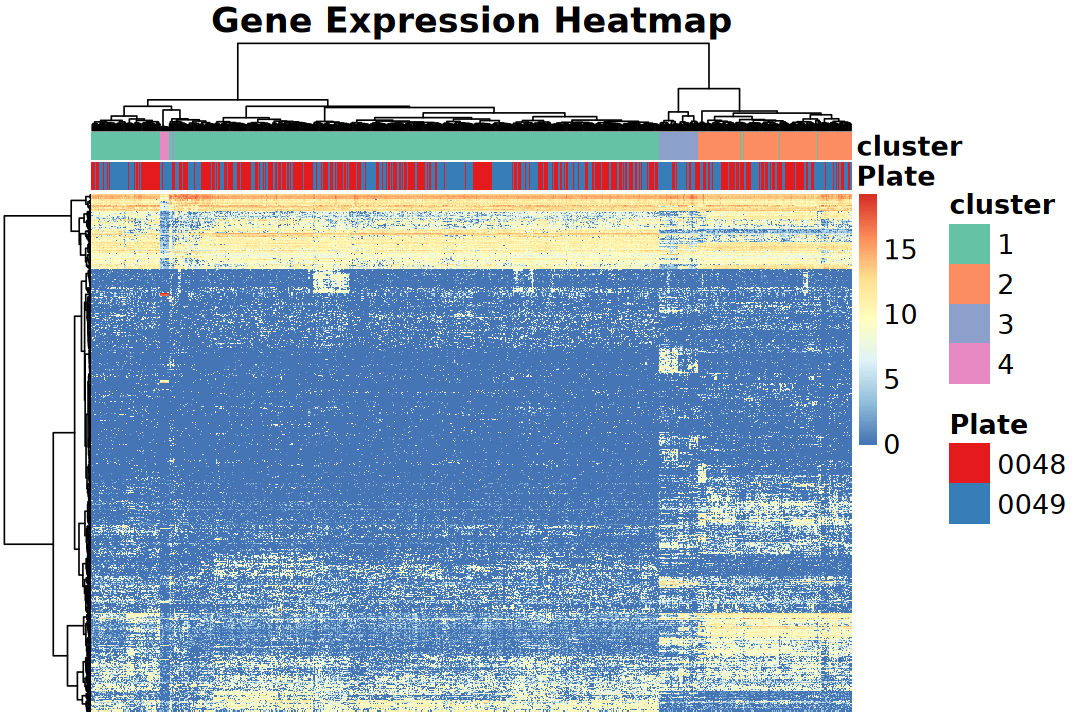

In [122]:
options(repr.plot.width = 9, repr.plot.height = 6)
pheatmap(normExpr[top_cv2_idx, ],
         annotation_col = ac, 
         annotation_colors = anno_colors, 
         clustering_distance_rows = "euclidean", 
         clustering_method = "ward.D2",
         main = "Gene Expression Heatmap", fontsize = 16, 
         show_colnames = FALSE, show_rownames = FALSE)